In [1]:
import numpy as np 
import xarray as xr
import matplotlib.pyplot as plt

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

import time
start_time = time.time()

In [2]:
def deseasonalize(data_arr):
    seasonal_mean = data_arr.groupby('time.dayofyear').mean(dim='time')
    tot_mean = data_arr.mean(dim='time')
    deseasonalized_data_arr = data_arr.groupby('time.dayofyear') - seasonal_mean + tot_mean
    return deseasonalized_data_arr

In [3]:
def detrend(da, dim='time', deg=1):
    # detrend along a single dimension
    p = da.polyfit(dim=dim, deg=deg)
    fit = xr.polyval(da[dim], p.polyfit_coefficients)
    mean = da.mean(dim)
    #print(da-fit+mean)
    return da - fit + mean

In [4]:
#!ATTENTION! this deseasonalization-detrending technique only works when dataset is all-year
def rm_deseasonalize_detrend(data_arr):
    rolling_mean = data_arr.rolling(time=90, center=True, min_periods=1).mean()
    tot_mean = data_arr.mean(dim='time')
    deseasonalized_data_arr = data_arr - rolling_mean + tot_mean
    return deseasonalized_data_arr

In [5]:
%cd /emmy-noether/home/mf671/DATA/ERA5/geop/
!ls

/emmy-noether/home/mf671/DATA/ERA5/geop
ERA5_2.5x2.5_zg500_daily_1940-2024.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023_deseasonalized.nc
ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_1960-1963.nc
ERA5_northem_2.5x2.5_zg500_daily_1960.nc
ERA5_northem_2.5x2.5_zg500_daily_jja_1940-2023.nc
ERA5_northem_2.5x2.5_zg500_daily_jja_1960-1970.nc
ERA5_northem_2.5x2.5_zg500_monthly_jja_1940-2023_detrended.nc
ERA5_northem_2.5x2.5_zg500_monthly_jja_1940-2023.nc
grid.txt
try.nc


In [6]:
ds = xr.open_dataset('ERA5_northem_2.5x2.5_zg500_daily_1940-2023.nc')
zg_baseline = ds['zg']
zg_des_det = detrend(deseasonalize(zg_baseline))
zg_rm_des_det = rm_deseasonalize_detrend(zg_baseline)

plot_levels = np.arange(0,30,1)

__Starting a GHA process__
input: zg500 , multiplicative threshold = 1.26


100%|███████████████████████████████████████████████████████████████| 30591/30591 [00:24<00:00, 1252.22it/s]


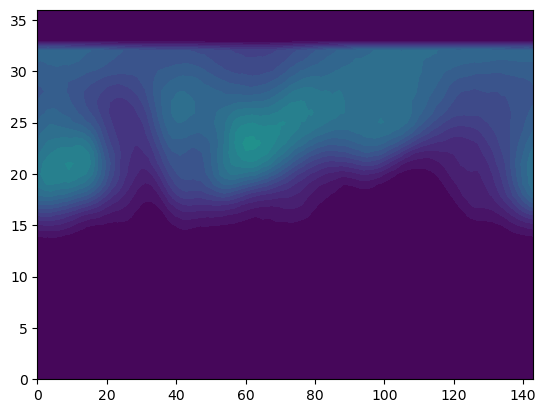

In [7]:
#BASELINE
ds_baseline = BT.GHA(ds,multiplicative_threshold=1.26)
plt.contourf(ds_baseline['GHA_freq'],plot_levels)

__Starting a GHA process__
input: zg500 , multiplicative threshold = 1.26


100%|████████████████████████████████████████████████████████████████| 30591/30591 [01:05<00:00, 468.50it/s]


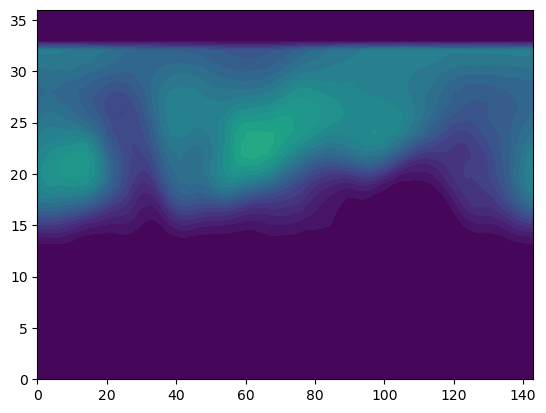

In [8]:
#DESEASONALIZATION 1
ds['zg'] = zg_des_det
ds_des_det = BT.GHA(ds,multiplicative_threshold=1.26)
plt.contourf(ds_des_det['GHA_freq'],plot_levels)

__Starting a GHA process__
input: zg500 , multiplicative threshold = 1.26


100%|███████████████████████████████████████████████████████████████| 30591/30591 [00:25<00:00, 1185.34it/s]


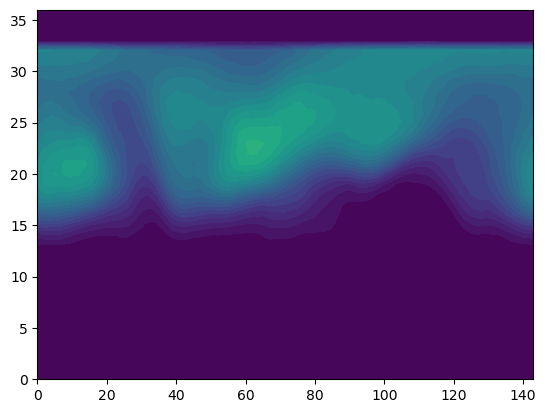

In [9]:
#DESEASONALIZATION 2
ds['zg'] = zg_rm_des_det
ds_rm_des_det = BT.GHA(ds,multiplicative_threshold=1.26)
plt.contourf(ds_rm_des_det['GHA_freq'],plot_levels)

In [11]:
from tqdm import tqdm

selected_months = [6,7,8]

bool_tss = []
for dataset in (ds_baseline,ds_des_det,ds_rm_des_det):
    dataset = dataset.where(dataset.time.dt.month.isin(selected_months), drop=True)
    bool_ts = []
    GHA_bool = dataset['GHA']
    counter = 0
    for t in tqdm(range(len(GHA_bool))):
        bool_ts.append(int(np.sum(GHA_bool[t,:,:].loc[60:80,-80:-20]).values))
    bool_tss.append(bool_ts)

100%|█████████████████████████████████████████████████████████████████| 7728/7728 [00:05<00:00, 1414.29it/s]


In [13]:
def simple_moving_average(data, window_size):
    return np.convolve(data, np.ones(window_size) / window_size, mode='valid')

In [14]:
frequencies = []
for bool_ts in bool_tss:
    freq_ts = simple_moving_average(bool_ts,30*3*10)
    frequencies.append((freq_ts-freq_ts[:30*3*40].mean())/freq_ts[:30*3*40].mean())

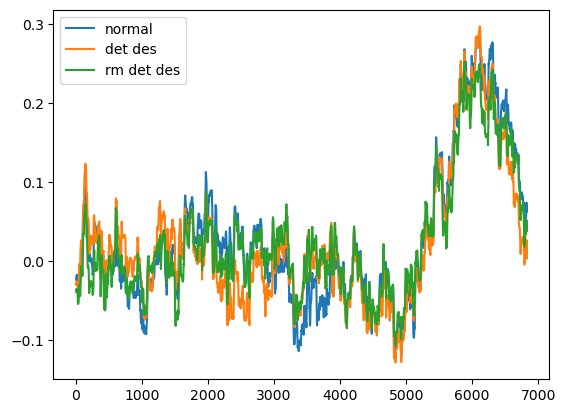

In [15]:
labels = ['normal','det des','rm det des']
#times = dataset['time']
for i,freq_ts in enumerate(frequencies):
    plt.plot(freq_ts,label=labels[i])
plt.legend()